<a href="https://colab.research.google.com/github/AyushM05/ECE562_Lab1/blob/main/Q1_FCNetworks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!unzip -q "/content/drive/MyDrive/ECE562_Lab1/Lab1_colab.zip" -d "/content/drive/MyDrive/ECE562_Lab1/"

replace /content/drive/MyDrive/ECE562_Lab1/assignment1_colab/assignment1/.ipynb_checkpoints/desktop.ini? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [15]:
# this mounts your Google Drive to the Colab VM.
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

# enter the foldername in your Drive where you have saved the unzipped
# assignment folder, e.g. 'ece662/assignments/assignment3/'
FOLDERNAME = 'ECE562_Lab1/assignment1_colab/assignment1'
assert FOLDERNAME is not None, "[!] Enter the foldername."

# now that we've mounted your Drive, this ensures that
# the Python interpreter of the Colab VM can load
# python files from within it.
import sys
sys.path.append('/content/drive/My Drive/{}'.format(FOLDERNAME))

%cd /content

Mounted at /content/drive
/content


# Fully-Connected Neural Nets
In this exercise we will implement fully-connected networks using a modular approach. Ideally we want to build networks using a more modular design so that we can implement different layer types in isolation and then snap them together into models with different architectures. For each layer we will implement a `forward` and a `backward` function. The `forward` function will receive inputs, weights, and other parameters and will return both an output and a `cache` object storing data needed for the backward pass, like this:

```python
def layer_forward(x, w):
  """ Receive inputs x and weights w """
  # Do some computations ...
  z = # ... some intermediate value
  # Do some more computations ...
  out = # the output
   
  cache = (x, w, z, out) # Values we need to compute gradients
   
  return out, cache
```

The backward pass will receive upstream derivatives and the `cache` object, and will return gradients with respect to the inputs and weights, like this:

```python
def layer_backward(dout, cache):
  """
  Receive dout (derivative of loss with respect to outputs) and cache,
  and compute derivative with respect to inputs.
  """
  # Unpack cache values
  x, w, z, out = cache
  
  # Use values in cache to compute derivatives
  dx = # Derivative of loss with respect to x
  dw = # Derivative of loss with respect to w
  
  return dx, dw
```

After implementing a bunch of layers this way, we will be able to easily combine them to build classifiers with different architectures.

In addition to implementing fully-connected networks of arbitrary depth, we will also explore different update rules for optimization, and introduce Dropout as a regularizer and Batch/Layer Normalization as a tool to more efficiently optimize deep networks.
  

In [16]:
# As usual, a bit of setup
from __future__ import print_function
import time
import numpy as np
import matplotlib.pyplot as plt
from ece662.classifiers.fc_net import *
from ece662.data_utils import get_CINIC10_data
from ece662.gradient_check import eval_numerical_gradient, eval_numerical_gradient_array
from ece662.solver import Solver

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0) # set default size of plots
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

# for auto-reloading external modules
# see http://stackoverflow.com/questions/1907993/autoreload-of-modules-in-ipython
import sys, importlib
sys.modules['imp'] = importlib
%load_ext autoreload
%autoreload 2

def rel_error(x, y):
  """ returns relative error """
  return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [17]:
# Load the (preprocessed) CINIC10 data - Note that CINIC10 was modified in size for this course

data = get_CINIC10_data()
for k, v in list(data.items()):
  print(('%s: ' % k, v.shape))

print('Number of Classes: {}'.format(len(np.unique(data['y_train']))))

('X_train: ', (53973, 3, 32, 32))
('y_train: ', (53973,))
('X_val: ', (10195, 3, 32, 32))
('y_val: ', (10195,))
('X_test: ', (10196, 3, 32, 32))
('y_test: ', (10196,))
Number of Classes: 6


# Affine layer: forward
Open the file `ece662/layers.py` and implement the `affine_forward` function.

Once you are done you can test your implementaion by running the following:

In [3]:
# Test the affine_forward function

num_inputs = 2
input_shape = (4, 5, 6)
output_dim = 3

input_size = num_inputs * np.prod(input_shape)
weight_size = output_dim * np.prod(input_shape)

x = np.linspace(-0.1, 0.5, num=input_size).reshape(num_inputs, *input_shape)
w = np.linspace(-0.2, 0.3, num=weight_size).reshape(np.prod(input_shape), output_dim)
b = np.linspace(-0.3, 0.1, num=output_dim)

out, _ = affine_forward(x, w, b)
correct_out = np.array([[ 1.49834967,  1.70660132,  1.91485297],
                        [ 3.25553199,  3.5141327,   3.77273342]])

# Compare your output with ours. The error should be around e-9 or less.
print('Testing affine_forward function:')
print('difference: ', rel_error(out, correct_out))

Testing affine_forward function:
difference:  9.769849468192957e-10


# Affine layer: backward
Now implement the `affine_backward` function and test your implementation using numeric gradient checking.

In [4]:
# Test the affine_backward function
np.random.seed(231)
x = np.random.randn(10, 2, 3)
w = np.random.randn(6, 5)
b = np.random.randn(5)
dout = np.random.randn(10, 5)

dx_num = eval_numerical_gradient_array(lambda x: affine_forward(x, w, b)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: affine_forward(x, w, b)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: affine_forward(x, w, b)[0], b, dout)

_, cache = affine_forward(x, w, b)
dx, dw, db = affine_backward(dout, cache)

# The error should be around e-10 or less
print('Testing affine_backward function:')
print('dx error: ', rel_error(dx_num, dx))
print('dw error: ', rel_error(dw_num, dw))
print('db error: ', rel_error(db_num, db))

Testing affine_backward function:
dx error:  5.399100368651805e-11
dw error:  9.904211865398145e-11
db error:  2.4122867568119087e-11


# ReLU activation: forward
Implement the forward pass for the ReLU activation function in the `relu_forward` function and test your implementation using the following:

In [5]:
# Test the relu_forward function

x = np.linspace(-0.5, 0.5, num=12).reshape(3, 4)

out, _ = relu_forward(x)
correct_out = np.array([[ 0.,          0.,          0.,          0.,        ],
                        [ 0.,          0.,          0.04545455,  0.13636364,],
                        [ 0.22727273,  0.31818182,  0.40909091,  0.5,       ]])

# Compare your output with ours. The error should be on the order of e-8
print('Testing relu_forward function:')
print('difference: ', rel_error(out, correct_out))

Testing relu_forward function:
difference:  4.999999798022158e-08


# ReLU activation: backward
Now implement the backward pass for the ReLU activation function in the `relu_backward` function and test your implementation using numeric gradient checking:

In [6]:
np.random.seed(231)
x = np.random.randn(10, 10)
dout = np.random.randn(*x.shape)

dx_num = eval_numerical_gradient_array(lambda x: relu_forward(x)[0], x, dout)

_, cache = relu_forward(x)
dx = relu_backward(dout, cache)

# The error should be on the order of e-12
print('Testing relu_backward function:')
print('dx error: ', rel_error(dx_num, dx))

Testing relu_backward function:
dx error:  3.2756349136310288e-12


## Inline Question 1:

We've only asked you to implement ReLU, but there are a number of different activation functions that one could use in neural networks, each with its pros and cons. In particular, an issue commonly seen with activation functions is getting zero (or close to zero) gradient flow during backpropagation. Which of the following activation functions have this problem? If you consider these functions in the one dimensional case, what types of input would lead to this behaviour?
1. Sigmoid
2. Tanh

## Answer:

Both Sigmoid and Tanh are affected by this problem. This occurs when they receive really large positive or negative inputs. At these extremes, the functions saturate and flatten out, which means their local derivative approaches zero and kills the gradient flow.


## Inline Question 2:

Why is an activation function required ? Why is a bias required ?

## Answer:

The activation function brings non-linearity. Without it, stacking multiple affine layers would mathematically collapse into a single linear transformation, which would make deep networks impossible.

A bias shifts the activation function left or right. Without it, a layer is forced to pass exactly through the origin which would limit the model's ability to fit actual real world data.

# "Sandwich" layers
There are some common patterns of layers that are frequently used in neural nets. For example, affine layers are frequently followed by a ReLU nonlinearity. To make these common patterns easy, we define several convenience layers in the file `ece662/layer_utils.py`.

For now take a look at the `affine_relu_forward` and `affine_relu_backward` functions, and run the following to numerically gradient check the backward pass:

In [7]:
from ece662.layer_utils import affine_relu_forward, affine_relu_backward
np.random.seed(231)
x = np.random.randn(2, 3, 4)
w = np.random.randn(12, 10)
b = np.random.randn(10)
dout = np.random.randn(2, 10)

out, cache = affine_relu_forward(x, w, b)
dx, dw, db = affine_relu_backward(dout, cache)

dx_num = eval_numerical_gradient_array(lambda x: affine_relu_forward(x, w, b)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: affine_relu_forward(x, w, b)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: affine_relu_forward(x, w, b)[0], b, dout)

# Relative error should be around e-10 or less
print('Testing affine_relu_forward and affine_relu_backward:')
print('dx error: ', rel_error(dx_num, dx))
print('dw error: ', rel_error(dw_num, dw))
print('db error: ', rel_error(db_num, db))

Testing affine_relu_forward and affine_relu_backward:
dx error:  2.299579177309368e-11
dw error:  8.162011105764925e-11
db error:  7.826724021458994e-12


# Loss layers: Softmax and SVM
You implemented these loss functions in the last assignment, so we'll give them to you for free here. You should still make sure you understand how they work by looking at the implementations in `ece662/layers.py`.

You can make sure that the implementations are correct by running the following:

In [8]:
np.random.seed(231)
num_classes, num_inputs = 10, 50
x = 0.001 * np.random.randn(num_inputs, num_classes)
y = np.random.randint(num_classes, size=num_inputs)

dx_num = eval_numerical_gradient(lambda x: svm_loss(x, y)[0], x, verbose=False)
loss, dx = svm_loss(x, y)

# Test svm_loss function. Loss should be around 9 and dx error should be around the order of e-9
print('Testing svm_loss:')
print('loss: ', loss)
print('dx error: ', rel_error(dx_num, dx))

dx_num = eval_numerical_gradient(lambda x: softmax_loss(x, y)[0], x, verbose=False)
loss, dx = softmax_loss(x, y)

# Test softmax_loss function. Loss should be close to 2.3 and dx error should be around e-8
print('\nTesting softmax_loss:')
print('loss: ', loss)
print('dx error: ', rel_error(dx_num, dx))

Testing svm_loss:
loss:  8.999602749096233
dx error:  1.4021566006651672e-09

Testing softmax_loss:
loss:  2.302545844500738
dx error:  9.384673161989355e-09


# Weight Initialization and Signal Propagation

Deep neural networks repeatedly apply affine transformations followed by nonlinear
activation functions. The way weights are initialized can therefore have a large
effect on how signals propagate through a deep network.

If weights are initialized too small, activations may shrink as they pass through
many layers. If weights are initialized too large, activations may grow rapidly
and make optimization unstable.

In this section, you will study how different weight initialization strategies
affect activation propagation through a deep ReLU network.

We will compare the following initialization strategies:

1. Zero initialization
2. Small random initialization
3. Large random initialization
4. He initialization

For a ReLU network, He initialization uses

$$
W_{ij} \sim \mathcal{N}\left(0,\frac{2}{\mathrm{fan\_in}}\right)
$$

or equivalently,

$$
W = \sqrt{\frac{2}{\mathrm{fan\_in}}}\,\mathcal{N}(0,1)
$$

You will propagate the same input through several layers and observe how the
distribution of activations changes with depth.

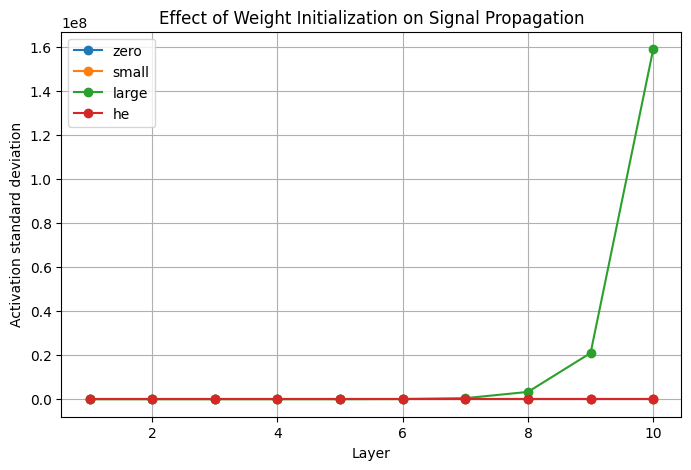


Initialization: zero
Layer  1: mean=  0.0000  std=  0.0000  zero_fraction= 1.000
Layer  2: mean=  0.0000  std=  0.0000  zero_fraction= 1.000
Layer  3: mean=  0.0000  std=  0.0000  zero_fraction= 1.000
Layer  4: mean=  0.0000  std=  0.0000  zero_fraction= 1.000
Layer  5: mean=  0.0000  std=  0.0000  zero_fraction= 1.000
Layer  6: mean=  0.0000  std=  0.0000  zero_fraction= 1.000
Layer  7: mean=  0.0000  std=  0.0000  zero_fraction= 1.000
Layer  8: mean=  0.0000  std=  0.0000  zero_fraction= 1.000
Layer  9: mean=  0.0000  std=  0.0000  zero_fraction= 1.000
Layer 10: mean=  0.0000  std=  0.0000  zero_fraction= 1.000

Initialization: small
Layer  1: mean=  0.0040  std=  0.0058  zero_fraction= 0.497
Layer  2: mean=  0.0000  std=  0.0000  zero_fraction= 0.515
Layer  3: mean=  0.0000  std=  0.0000  zero_fraction= 0.476
Layer  4: mean=  0.0000  std=  0.0000  zero_fraction= 0.495
Layer  5: mean=  0.0000  std=  0.0000  zero_fraction= 0.465
Layer  6: mean=  0.0000  std=  0.0000  zero_fraction= 0

In [9]:
# Weight initialization experiment

np.random.seed(42)

N = 200          # Number of input samples
input_dim = 100  # Input dimension
hidden_dim = 100
num_layers = 10

X = np.random.randn(N, input_dim)

initialization_schemes = [
    "zero",
    "small",
    "large",
    "he",
]

activation_stats = {}

for init_type in initialization_schemes:

    x = X.copy()

    layer_means = []
    layer_stds = []
    layer_zero_fractions = []

    for layer in range(num_layers):

        fan_in = x.shape[1]

        #######################################################################
        # TODO: Initialize the weight matrix W according to init_type.        #
        #                                                                     #
        # Use the following initialization schemes:                           #
        #                                                                     #
        # zero:                                                               #
        #     All weights should be zero.                                     #
        #                                                                     #
        # small:                                                              #
        #     Draw weights from a standard normal distribution and multiply   #
        #     them by 1e-3.                                                   #
        #                                                                     #
        # large:                                                              #
        #     Draw weights from a standard normal distribution.               #
        #                                                                     #
        # he:                                                                 #
        #     Draw weights from a standard normal distribution and scale      #
        #     using sqrt(2 / fan_in).                                         #
        #                                                                     #
        # W should have shape (fan_in, hidden_dim).                           #
        #######################################################################
        # *****START OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****

        if init_type == 'zero':
          W = np.zeros((input_dim, hidden_dim))
        elif init_type == 'small':
          W = np.random.randn(input_dim, hidden_dim) * 1e-3
        elif init_type == 'large':
          W = np.random.randn(input_dim, hidden_dim)
        elif init_type == 'he':
          W = np.random.randn(input_dim, hidden_dim) * np.sqrt(2.0 / input_dim)

        # *****END OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
        #######################################################################
        #                           END OF YOUR CODE                          #
        #######################################################################

        #######################################################################
        # TODO: Compute the affine transformation followed by ReLU.           #
        # Store the resulting activation back into x.                         #
        #######################################################################
        # *****START OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****

        x = np.maximum(0, x.dot(W))

        # *****END OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
        #######################################################################
        #                           END OF YOUR CODE                          #
        #######################################################################

        layer_means.append(np.mean(x))
        layer_stds.append(np.std(x))
        layer_zero_fractions.append(np.mean(x == 0))

    activation_stats[init_type] = {
        "mean": layer_means,
        "std": layer_stds,
        "zero_fraction": layer_zero_fractions,
    }


# Plot activation standard deviation across layers
plt.figure(figsize=(8, 5))

for init_type in initialization_schemes:
    plt.plot(
        range(1, num_layers + 1),
        activation_stats[init_type]["std"],
        marker="o",
        label=init_type,
    )

plt.xlabel("Layer")
plt.ylabel("Activation standard deviation")
plt.title("Effect of Weight Initialization on Signal Propagation")
plt.legend()
plt.grid(True)
plt.show()


# Print statistics for easier comparison
for init_type in initialization_schemes:
    print("\nInitialization:", init_type)

    for layer in range(num_layers):
        print(
            "Layer %2d: mean=%8.4f  std=%8.4f  zero_fraction=%6.3f"
            % (
                layer + 1,
                activation_stats[init_type]["mean"][layer],
                activation_stats[init_type]["std"][layer],
                activation_stats[init_type]["zero_fraction"][layer],
            )
        )

## Inline Question 3: Weight Initialization

Using the results from the experiment above, answer the following questions.

1. What happens to the activations when all weights are initialized to zero?
   In addition to the behavior you observe above, explain why initializing all
   neurons identically prevents effective symmetry breaking during training.

2. What happens to the activation standard deviation as the network becomes
   deeper when using the small random initialization?

3. What happens when the weights are initialized using the large random
   initialization? How might this affect numerical stability and optimization?

4. How does He initialization behave compared with the other initialization
   strategies? Why is the factor

$$
\sqrt{\frac{2}{\mathrm{fan\_in}}}
$$

particularly appropriate for networks using ReLU activations?

5. Consider the following implementation:

        W = np.random.randn(fan_in, fan_out) * np.sqrt(2.0 / fan_out)

   Is this consistent with the He initialization introduced above?
   If not, correct the expression and explain why the scaling depends on the
   number of inputs to each neuron rather than the number of outputs.

6. Does changing the initialization strategy change the number of
   multiply-accumulate operations (MACs) required for a single forward pass
   through the network?

   If a poor initialization requires significantly more training epochs to
   reach a target accuracy, what happens to the total amount of computation
   required for training?

## Answer:

1. Activations become zero. All neurons receive identical gradients during backpropagation, and updating symmetrically and failing to learn distinct and complex features.

2. The standard deviation of activations rapidly collapses toward zero in deeper layers, which actually destroy the signal and stop gradient flow.

3. Activations explode in magnitude. This pushes the inputs into the saturated outer bounds of non-linear functions, which cause numerical instablitiy and gradients to go away.

4. It maintains a consistent variance across layers. The factor $$
\sqrt{\frac{2}{\mathrm{fan\_in}}}
$$ mathematically offsets the fact that ReLU zeros out roughly half of its inputs, which prevents variance collapse.

5. The implementation is incorrect because it uses fan_out instead of fan_in. The scaling must depend on the number of inputs, in this case fan_in, to correctly normalize the variance of the weighted sum entering the neuron.

6. The initialization strategy doesn't change the number of MACs in a single forward pass. However, requiring significantly more epochs directly multiplies the total MACs computed over the entire training lifecycle.

# Two-layer network
In the previous assignment you implemented a two-layer neural network in a single monolithic class. Now that you have implemented modular versions of the necessary layers, you will reimplement the two layer network using these modular implementations.

Open the file `ece662/classifiers/fc_net.py` and complete the implementation of the `TwoLayerNet` class. This class will serve as a model for the other networks you will implement in this assignment, so read through it to make sure you understand the API. You can run the cell below to test your implementation.

In [13]:
np.random.seed(231)
N, D, H, C = 3, 5, 50, 7
X = np.random.randn(N, D)
y = np.random.randint(C, size=N)

std = 1e-3
model = TwoLayerNet(input_dim=D, hidden_dim=H, num_classes=C, weight_scale=std)

print('Testing initialization ... ')
W1_std = abs(model.params['W1'].std() - std)
b1 = model.params['b1']
W2_std = abs(model.params['W2'].std() - std)
b2 = model.params['b2']
assert W1_std < std / 10, 'First layer weights do not seem right'
assert np.all(b1 == 0), 'First layer biases do not seem right'
assert W2_std < std / 10, 'Second layer weights do not seem right'
assert np.all(b2 == 0), 'Second layer biases do not seem right'

print('Testing test-time forward pass ... ')
model.params['W1'] = np.linspace(-0.7, 0.3, num=D*H).reshape(D, H)
model.params['b1'] = np.linspace(-0.1, 0.9, num=H)
model.params['W2'] = np.linspace(-0.3, 0.4, num=H*C).reshape(H, C)
model.params['b2'] = np.linspace(-0.9, 0.1, num=C)
X = np.linspace(-5.5, 4.5, num=N*D).reshape(D, N).T
scores = model.loss(X)
correct_scores = np.asarray(
  [[11.53165108,  12.2917344,   13.05181771,  13.81190102,  14.57198434, 15.33206765,  16.09215096],
   [12.05769098,  12.74614105,  13.43459113,  14.1230412,   14.81149128, 15.49994135,  16.18839143],
   [12.58373087,  13.20054771,  13.81736455,  14.43418138,  15.05099822, 15.66781506,  16.2846319 ]])
scores_diff = np.abs(scores - correct_scores).sum()
assert scores_diff < 1e-6, 'Problem with test-time forward pass'

print('Testing training loss (no regularization)')
y = np.asarray([0, 5, 1])
loss, grads = model.loss(X, y)
correct_loss = 3.4702243556
assert abs(loss - correct_loss) < 1e-10, 'Problem with training-time loss'

model.reg = 1.0
loss, grads = model.loss(X, y)
correct_loss = 26.5948426952
assert abs(loss - correct_loss) < 1e-10, 'Problem with regularization loss'

# Errors should be around e-7 or less
for reg in [0.0, 0.7]:
  print('Running numeric gradient check with reg = ', reg)
  model.reg = reg
  loss, grads = model.loss(X, y)

  for name in sorted(grads):
    f = lambda _: model.loss(X, y)[0]
    grad_num = eval_numerical_gradient(f, model.params[name], verbose=False)
    print('%s relative error: %.2e' % (name, rel_error(grad_num, grads[name])))

Testing initialization ... 
Testing test-time forward pass ... 
Testing training loss (no regularization)
Running numeric gradient check with reg =  0.0
W1 relative error: 1.83e-08
W2 relative error: 3.12e-10
b1 relative error: 9.83e-09
b2 relative error: 4.33e-10
Running numeric gradient check with reg =  0.7
W1 relative error: 2.53e-07
W2 relative error: 2.85e-08
b1 relative error: 1.56e-08
b2 relative error: 7.76e-10


# Solver
In the previous assignment, the logic for training models was coupled to the models themselves. Following a more modular design, for this assignment we have split the logic for training models into a separate class.

Open the file `ece662/solver.py` and read through it to familiarize yourself with the API. After doing so, use a `Solver` instance to train a `TwoLayerNet` that achieves at least `50%` accuracy on the validation set.

In [19]:
model = TwoLayerNet()
solver = None

##############################################################################
# TODO: Use a Solver instance to train a TwoLayerNet that achieves at least  #
# 50% accuracy on the validation set.                                        #
##############################################################################
# *****START OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****

# Initializing the model
model = TwoLayerNet(hidden_dim=100, reg=1e-3)

# Initializing the solver
solver = Solver(model, data,
                update_rule='sgd',
                optim_config={
                  'learning_rate': 1e-3,
                },
                lr_decay=0.95,
                num_epochs=10, batch_size=100,
                print_every=100)

# Run it
solver.train()

# *****END OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
##############################################################################
#                             END OF YOUR CODE                               #
##############################################################################

(Iteration 1 / 5390) loss: 2.301155
(Epoch 0 / 10) train acc: 0.181000; val_acc: 0.177832
(Iteration 101 / 5390) loss: 1.565502
(Iteration 201 / 5390) loss: 1.618683
(Iteration 301 / 5390) loss: 1.539778
(Iteration 401 / 5390) loss: 1.521396
(Iteration 501 / 5390) loss: 1.535304
(Epoch 1 / 10) train acc: 0.399000; val_acc: 0.373222
(Iteration 601 / 5390) loss: 1.546570
(Iteration 701 / 5390) loss: 1.661342
(Iteration 801 / 5390) loss: 1.459532
(Iteration 901 / 5390) loss: 1.600497
(Iteration 1001 / 5390) loss: 1.576790
(Epoch 2 / 10) train acc: 0.412000; val_acc: 0.385777
(Iteration 1101 / 5390) loss: 1.333538
(Iteration 1201 / 5390) loss: 1.512615
(Iteration 1301 / 5390) loss: 1.406134
(Iteration 1401 / 5390) loss: 1.447644
(Iteration 1501 / 5390) loss: 1.381139
(Iteration 1601 / 5390) loss: 1.500328
(Epoch 3 / 10) train acc: 0.444000; val_acc: 0.399804
(Iteration 1701 / 5390) loss: 1.444941
(Iteration 1801 / 5390) loss: 1.466476
(Iteration 1901 / 5390) loss: 1.291441
(Iteration 2001 

In [ ]:
# Run this cell to visualize training loss and train / val accuracy

plt.subplot(2, 1, 1)
plt.title('Training loss')
plt.plot(solver.loss_history, 'o')
plt.xlabel('Iteration')

plt.subplot(2, 1, 2)
plt.title('Accuracy')
plt.plot(solver.train_acc_history, '-o', label='train')
plt.plot(solver.val_acc_history, '-o', label='val')
plt.plot([0.5] * len(solver.val_acc_history), 'k--')
plt.xlabel('Epoch')
plt.legend(loc='lower right')
plt.gcf().set_size_inches(15, 12)
plt.show()

# Multilayer network
Next you will implement a fully-connected network with an arbitrary number of hidden layers.

Read through the `FullyConnectedNet` class in the file `ece662/classifiers/fc_net.py`.

Implement the initialization, the forward pass, and the backward pass. For the moment don't worry about implementing dropout or batch/layer normalization; we will add those features soon.

## Initial loss and gradient check

As a sanity check, run the following to check the initial loss and to gradient check the network both with and without regularization. Do the initial losses seem reasonable?

For gradient checking, you should expect to see errors around 1e-7 or less.

In [20]:
np.random.seed(231)
N, D, H1, H2, C = 2, 15, 20, 30, 10
X = np.random.randn(N, D)
y = np.random.randint(C, size=(N,))

for reg in [0, 3.14]:
  print('Running check with reg = ', reg)
  model = FullyConnectedNet([H1, H2], input_dim=D, num_classes=C,
                            reg=reg, weight_scale=5e-2, dtype=np.float64)

  loss, grads = model.loss(X, y)
  print('Initial loss: ', loss)

  # Most of the errors should be on the order of e-7 or smaller.
  # NOTE: It is fine however to see an error for W2 on the order of e-5
  # for the check when reg = 0.0
  for name in sorted(grads):
    f = lambda _: model.loss(X, y)[0]
    grad_num = eval_numerical_gradient(f, model.params[name], verbose=False, h=1e-5)
    print('%s relative error: %.2e' % (name, rel_error(grad_num, grads[name])))

Running check with reg =  0
Initial loss:  2.3004790897684924
W1 relative error: 1.48e-07
W2 relative error: 2.21e-05
W3 relative error: 3.53e-07
b1 relative error: 5.38e-09
b2 relative error: 2.09e-09
b3 relative error: 5.80e-11
Running check with reg =  3.14
Initial loss:  7.052114776533016
W1 relative error: 3.90e-09
W2 relative error: 6.87e-08
W3 relative error: 2.13e-08
b1 relative error: 1.48e-08
b2 relative error: 1.72e-09
b3 relative error: 1.57e-10


As another sanity check, make sure you can overfit a small dataset of 50 images. First we will try a three-layer network with 100 units in each hidden layer. In the following cell, tweak the **learning rate** and **weight initialization scale** to overfit and achieve 90+% training accuracy within 20 epochs.

(Iteration 1 / 40) loss: 1.806892
(Epoch 0 / 20) train acc: 0.300000; val_acc: 0.198431
(Epoch 1 / 20) train acc: 0.320000; val_acc: 0.206376
(Epoch 2 / 20) train acc: 0.360000; val_acc: 0.189308
(Epoch 3 / 20) train acc: 0.600000; val_acc: 0.217656
(Epoch 4 / 20) train acc: 0.540000; val_acc: 0.217656
(Epoch 5 / 20) train acc: 0.760000; val_acc: 0.186758
(Iteration 11 / 40) loss: 0.986982
(Epoch 6 / 20) train acc: 0.820000; val_acc: 0.232075
(Epoch 7 / 20) train acc: 0.940000; val_acc: 0.216381
(Epoch 8 / 20) train acc: 0.960000; val_acc: 0.227857
(Epoch 9 / 20) train acc: 1.000000; val_acc: 0.224816
(Epoch 10 / 20) train acc: 1.000000; val_acc: 0.233055
(Iteration 21 / 40) loss: 0.191172
(Epoch 11 / 20) train acc: 1.000000; val_acc: 0.234723
(Epoch 12 / 20) train acc: 1.000000; val_acc: 0.232565
(Epoch 13 / 20) train acc: 1.000000; val_acc: 0.227268
(Epoch 14 / 20) train acc: 1.000000; val_acc: 0.231878
(Epoch 15 / 20) train acc: 1.000000; val_acc: 0.234821
(Iteration 31 / 40) loss: 

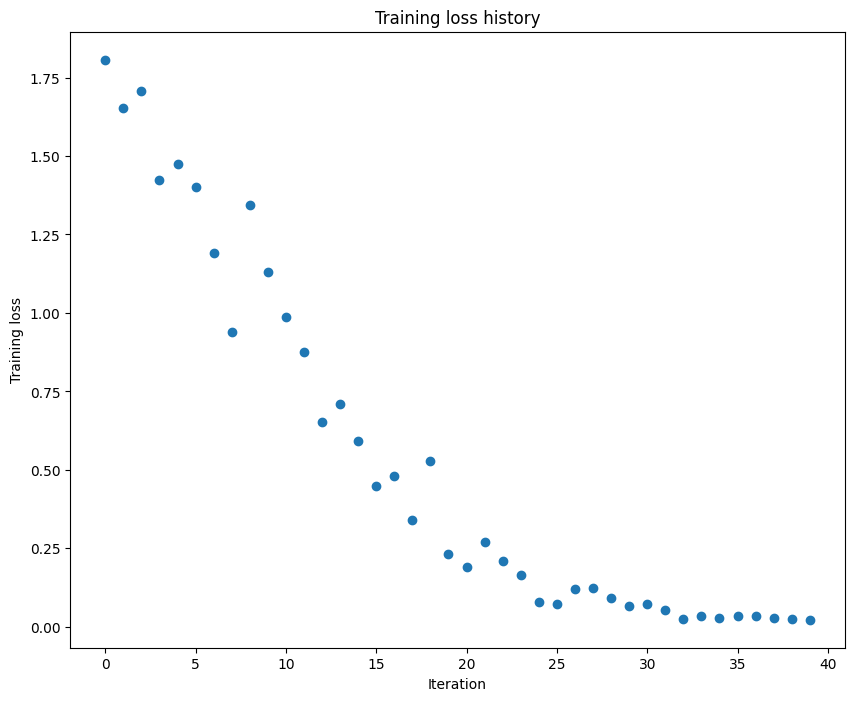

In [21]:
# TODO: Use a three-layer Net to overfit 50 training examples by
# tweaking just the learning rate and initialization scale.

num_train = 50
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

weight_scale = 1e-2   # Experiment with this!
learning_rate = 1e-2  # Experiment with this!
model = FullyConnectedNet([100, 100],
              weight_scale=weight_scale, dtype=np.float64, num_classes=6)
solver = Solver(model, small_data,
                print_every=10, num_epochs=20, batch_size=25,
                update_rule='sgd',
                optim_config={
                  'learning_rate': learning_rate,
                }
         )
solver.train()

plt.plot(solver.loss_history, 'o')
plt.title('Training loss history')
plt.xlabel('Iteration')
plt.ylabel('Training loss')
plt.show()

Now try to use a five-layer network with 100 units on each layer to overfit 50 training examples. Again, you will have to adjust the learning rate and weight initialization scale, but you should be able to achieve 100% training accuracy within 20 epochs.

(Iteration 1 / 40) loss: 5.636425
(Epoch 0 / 20) train acc: 0.140000; val_acc: 0.121432
(Epoch 1 / 20) train acc: 0.140000; val_acc: 0.130358
(Epoch 2 / 20) train acc: 0.240000; val_acc: 0.150662
(Epoch 3 / 20) train acc: 0.420000; val_acc: 0.159294
(Epoch 4 / 20) train acc: 0.500000; val_acc: 0.165375
(Epoch 5 / 20) train acc: 0.480000; val_acc: 0.169299
(Iteration 11 / 40) loss: 1.016064
(Epoch 6 / 20) train acc: 0.660000; val_acc: 0.172437
(Epoch 7 / 20) train acc: 0.680000; val_acc: 0.177342
(Epoch 8 / 20) train acc: 0.700000; val_acc: 0.173713
(Epoch 9 / 20) train acc: 0.820000; val_acc: 0.176459
(Epoch 10 / 20) train acc: 0.820000; val_acc: 0.174497
(Iteration 21 / 40) loss: 1.012993
(Epoch 11 / 20) train acc: 0.840000; val_acc: 0.177146
(Epoch 12 / 20) train acc: 0.860000; val_acc: 0.173320
(Epoch 13 / 20) train acc: 0.900000; val_acc: 0.174105
(Epoch 14 / 20) train acc: 0.900000; val_acc: 0.177734
(Epoch 15 / 20) train acc: 0.920000; val_acc: 0.177146
(Iteration 31 / 40) loss: 

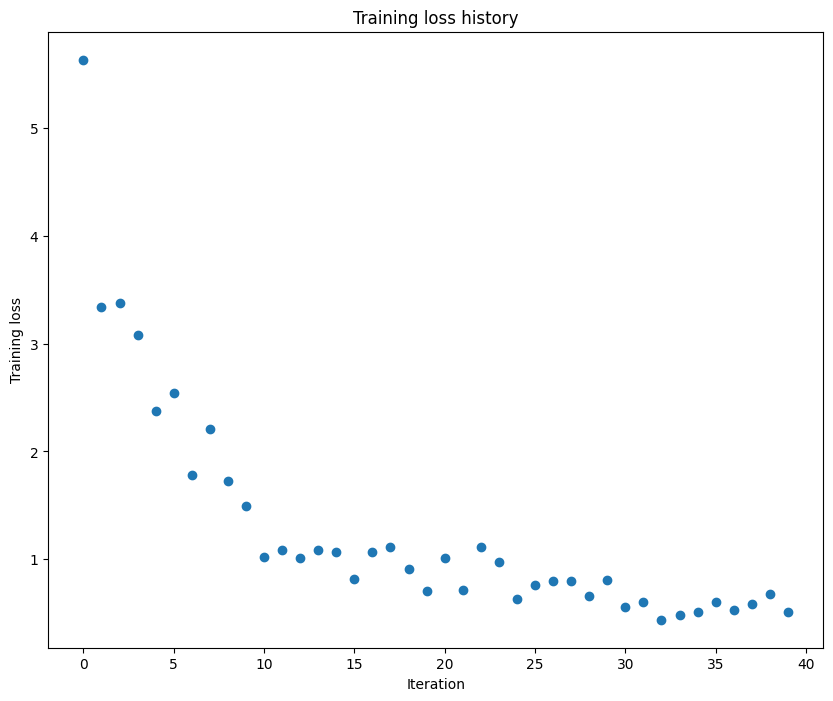

In [29]:
# TODO: Use a five-layer Net to overfit 50 training examples by
# tweaking just the learning rate and initialization scale.

num_train = 50
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

learning_rate = 1e-3  # Experiment with this!
weight_scale = 5e-2   # Experiment with this!
model = FullyConnectedNet([100, 100, 100, 100],
                weight_scale=weight_scale, dtype=np.float64)
solver = Solver(model, small_data,
                print_every=10, num_epochs=20, batch_size=25,
                update_rule='sgd',
                optim_config={
                  'learning_rate': learning_rate,
                }
         )
solver.train()

plt.plot(solver.loss_history, 'o')
plt.title('Training loss history')
plt.xlabel('Iteration')
plt.ylabel('Training loss')
plt.show()

## Inline Question 4:
Why would you need multi-layer networks ? Will stacking several layers without activation functions be able to model complex problems ?

## Answer:

Multi-layer networks are needed to learn hierarchal, non-linear representations of data, such as combining simple edges into complex shapes. Stacking several layers without activation funcitons mathematically collapses into a single linear matrix transformation (W_2(W_1 * X) = W_combined * X), which makes it incapable of modeling complex, non-linear decision boundaries.

# Update rules
So far we have used vanilla stochastic gradient descent (SGD) as our update rule. More sophisticated update rules can make it easier to train deep networks. We will implement a few of the most commonly used update rules and compare them to vanilla SGD.

# SGD+Momentum
Stochastic gradient descent with momentum is a widely used update rule that tends to make deep networks converge faster than vanilla stochastic gradient descent.

Open the file `ece662/optim.py` and read the documentation at the top of the file to make sure you understand the API. Implement the SGD+momentum update rule in the function `sgd_momentum` and run the following to check your implementation. You should see errors less than e-8.

In [31]:
from ece662.optim import sgd_momentum

N, D = 4, 5
w = np.linspace(-0.4, 0.6, num=N*D).reshape(N, D)
dw = np.linspace(-0.6, 0.4, num=N*D).reshape(N, D)
v = np.linspace(0.6, 0.9, num=N*D).reshape(N, D)

config = {'learning_rate': 1e-3, 'velocity': v}
next_w, _ = sgd_momentum(w, dw, config=config)

expected_next_w = np.asarray([
  [ 0.1406,      0.20738947,  0.27417895,  0.34096842,  0.40775789],
  [ 0.47454737,  0.54133684,  0.60812632,  0.67491579,  0.74170526],
  [ 0.80849474,  0.87528421,  0.94207368,  1.00886316,  1.07565263],
  [ 1.14244211,  1.20923158,  1.27602105,  1.34281053,  1.4096    ]])
expected_velocity = np.asarray([
  [ 0.5406,      0.55475789,  0.56891579, 0.58307368,  0.59723158],
  [ 0.61138947,  0.62554737,  0.63970526,  0.65386316,  0.66802105],
  [ 0.68217895,  0.69633684,  0.71049474,  0.72465263,  0.73881053],
  [ 0.75296842,  0.76712632,  0.78128421,  0.79544211,  0.8096    ]])

# Should see relative errors around e-8 or less
print('next_w error: ', rel_error(next_w, expected_next_w))
print('velocity error: ', rel_error(expected_velocity, config['velocity']))

next_w error:  8.882347033505819e-09
velocity error:  4.269287743278663e-09


Once you have done so, run the following to train a six-layer network with both SGD and SGD+momentum. You should see the SGD+momentum update rule converge faster.

running with  sgd
(Iteration 1 / 200) loss: 2.391364
(Epoch 0 / 5) train acc: 0.182000; val_acc: 0.166160
(Iteration 11 / 200) loss: 1.749161
(Iteration 21 / 200) loss: 1.787871
(Iteration 31 / 200) loss: 1.725959
(Epoch 1 / 5) train acc: 0.249000; val_acc: 0.226778
(Iteration 41 / 200) loss: 1.724006
(Iteration 51 / 200) loss: 1.781307
(Iteration 61 / 200) loss: 1.695475
(Iteration 71 / 200) loss: 1.693110
(Epoch 2 / 5) train acc: 0.319000; val_acc: 0.254733
(Iteration 81 / 200) loss: 1.609009
(Iteration 91 / 200) loss: 1.715701
(Iteration 101 / 200) loss: 1.670172
(Iteration 111 / 200) loss: 1.571517
(Epoch 3 / 5) train acc: 0.346000; val_acc: 0.270329
(Iteration 121 / 200) loss: 1.667944
(Iteration 131 / 200) loss: 1.466899
(Iteration 141 / 200) loss: 1.601903
(Iteration 151 / 200) loss: 1.654444
(Epoch 4 / 5) train acc: 0.352000; val_acc: 0.277685
(Iteration 161 / 200) loss: 1.488006
(Iteration 171 / 200) loss: 1.534169
(Iteration 181 / 200) loss: 1.453644
(Iteration 191 / 200) los

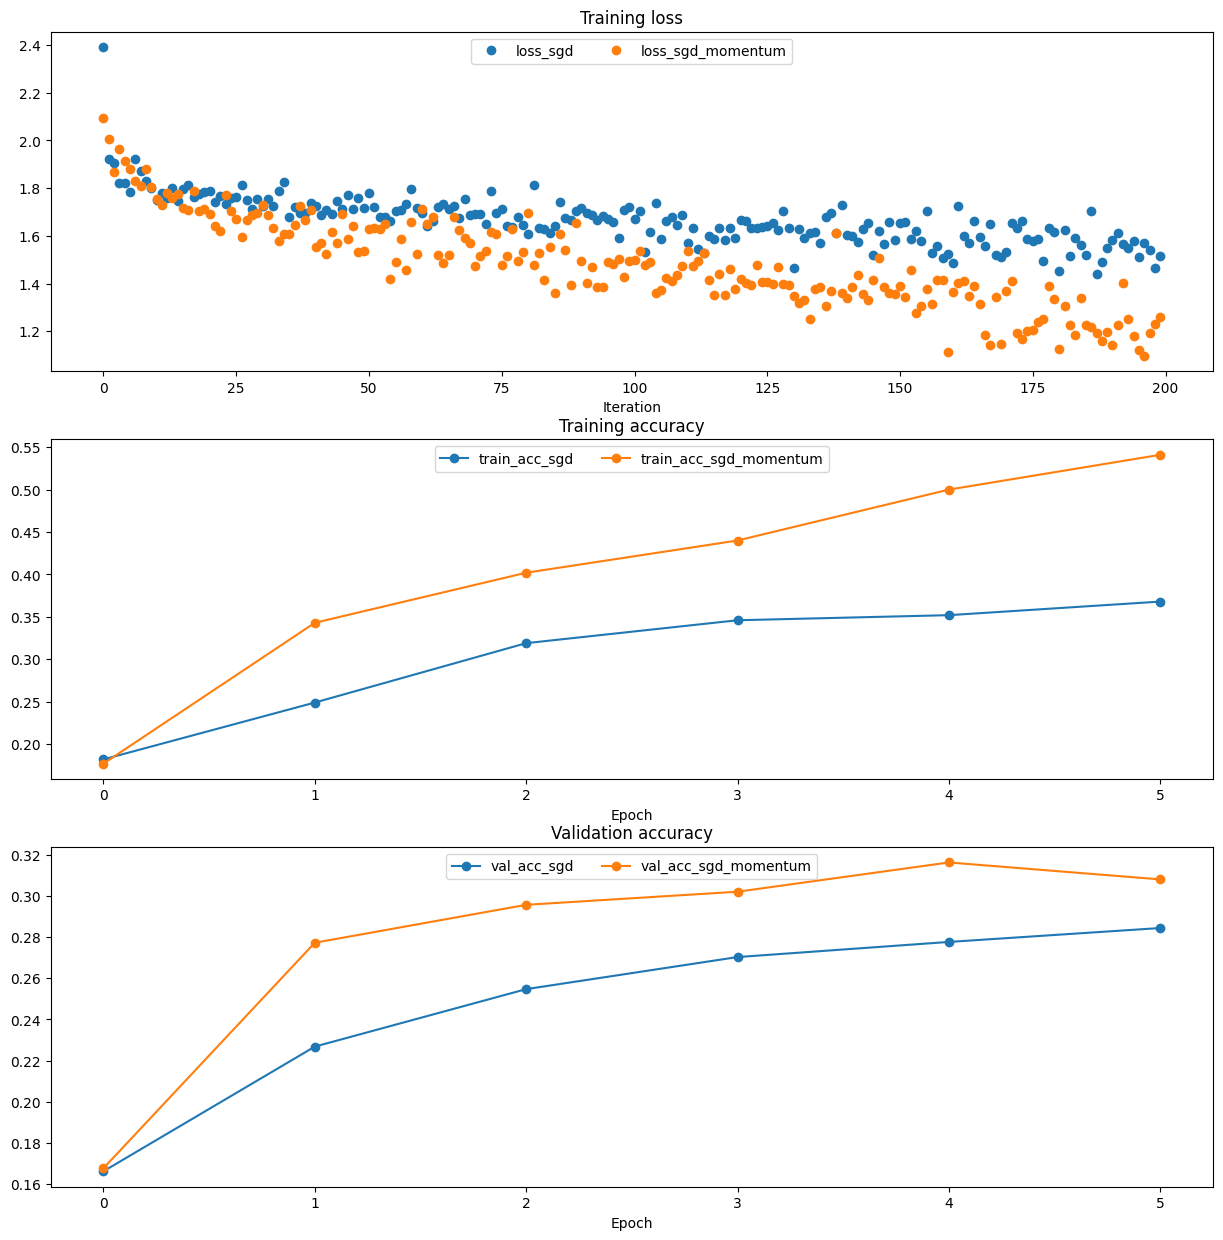

In [32]:
num_train = 4000
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

solvers = {}

for update_rule in ['sgd', 'sgd_momentum']:
  print('running with ', update_rule)
  model = FullyConnectedNet([100, 100, 100, 100, 100], weight_scale=5e-2, num_classes=6)

  solver = Solver(model, small_data,
                  num_epochs=5, batch_size=100,
                  update_rule=update_rule,
                  optim_config={
                    'learning_rate': 5e-3,
                  },
                  verbose=True)
  solvers[update_rule] = solver
  solver.train()
  print()

plt.subplot(3, 1, 1)
plt.title('Training loss')
plt.xlabel('Iteration')

plt.subplot(3, 1, 2)
plt.title('Training accuracy')
plt.xlabel('Epoch')

plt.subplot(3, 1, 3)
plt.title('Validation accuracy')
plt.xlabel('Epoch')

for update_rule, solver in solvers.items():
  plt.subplot(3, 1, 1)
  plt.plot(solver.loss_history, 'o', label="loss_%s" % update_rule)

  plt.subplot(3, 1, 2)
  plt.plot(solver.train_acc_history, '-o', label="train_acc_%s" % update_rule)

  plt.subplot(3, 1, 3)
  plt.plot(solver.val_acc_history, '-o', label="val_acc_%s" % update_rule)

for i in [1, 2, 3]:
  plt.subplot(3, 1, i)
  plt.legend(loc='upper center', ncol=4)
plt.gcf().set_size_inches(15, 15)
plt.show()

# RMSProp and Adam
RMSProp [1] and Adam [2] are update rules that set per-parameter learning rates by using a running average of the second moments of gradients.

In the file `ece662/optim.py`, implement the RMSProp update rule in the `rmsprop` function and implement the Adam update rule in the `adam` function, and check your implementations using the tests below.

**NOTE:** Please implement the _complete_ Adam update rule (with the bias correction mechanism), not the first simplified version mentioned in the course notes.

[1] Tijmen Tieleman and Geoffrey Hinton. "Lecture 6.5-rmsprop: Divide the gradient by a running average of its recent magnitude." COURSERA: Neural Networks for Machine Learning 4 (2012).

[2] Diederik Kingma and Jimmy Ba, "Adam: A Method for Stochastic Optimization", ICLR 2015.

In [33]:
# Test RMSProp implementation
from ece662.optim import rmsprop

N, D = 4, 5
w = np.linspace(-0.4, 0.6, num=N*D).reshape(N, D)
dw = np.linspace(-0.6, 0.4, num=N*D).reshape(N, D)
cache = np.linspace(0.6, 0.9, num=N*D).reshape(N, D)

config = {'learning_rate': 1e-2, 'cache': cache}
next_w, _ = rmsprop(w, dw, config=config)

expected_next_w = np.asarray([
  [-0.39223849, -0.34037513, -0.28849239, -0.23659121, -0.18467247],
  [-0.132737,   -0.08078555, -0.02881884,  0.02316247,  0.07515774],
  [ 0.12716641,  0.17918792,  0.23122175,  0.28326742,  0.33532447],
  [ 0.38739248,  0.43947102,  0.49155973,  0.54365823,  0.59576619]])
expected_cache = np.asarray([
  [ 0.5976,      0.6126277,   0.6277108,   0.64284931,  0.65804321],
  [ 0.67329252,  0.68859723,  0.70395734,  0.71937285,  0.73484377],
  [ 0.75037008,  0.7659518,   0.78158892,  0.79728144,  0.81302936],
  [ 0.82883269,  0.84469141,  0.86060554,  0.87657507,  0.8926    ]])

# You should see relative errors around e-7 or less
print('next_w error: ', rel_error(expected_next_w, next_w))
print('cache error: ', rel_error(expected_cache, config['cache']))

next_w error:  9.524687511038133e-08
cache error:  2.6477955807156126e-09


In [34]:
# Test Adam implementation
from ece662.optim import adam

N, D = 4, 5
w = np.linspace(-0.4, 0.6, num=N*D).reshape(N, D)
dw = np.linspace(-0.6, 0.4, num=N*D).reshape(N, D)
m = np.linspace(0.6, 0.9, num=N*D).reshape(N, D)
v = np.linspace(0.7, 0.5, num=N*D).reshape(N, D)

config = {'learning_rate': 1e-2, 'm': m, 'v': v, 't': 5}
next_w, _ = adam(w, dw, config=config)

expected_next_w = np.asarray([
  [-0.40094747, -0.34836187, -0.29577703, -0.24319299, -0.19060977],
  [-0.1380274,  -0.08544591, -0.03286534,  0.01971428,  0.0722929],
  [ 0.1248705,   0.17744702,  0.23002243,  0.28259667,  0.33516969],
  [ 0.38774145,  0.44031188,  0.49288093,  0.54544852,  0.59801459]])
expected_v = np.asarray([
  [ 0.69966,     0.68908382,  0.67851319,  0.66794809,  0.65738853,],
  [ 0.64683452,  0.63628604,  0.6257431,   0.61520571,  0.60467385,],
  [ 0.59414753,  0.58362676,  0.57311152,  0.56260183,  0.55209767,],
  [ 0.54159906,  0.53110598,  0.52061845,  0.51013645,  0.49966,   ]])
expected_m = np.asarray([
  [ 0.48,        0.49947368,  0.51894737,  0.53842105,  0.55789474],
  [ 0.57736842,  0.59684211,  0.61631579,  0.63578947,  0.65526316],
  [ 0.67473684,  0.69421053,  0.71368421,  0.73315789,  0.75263158],
  [ 0.77210526,  0.79157895,  0.81105263,  0.83052632,  0.85      ]])

# You should see relative errors around e-7 or less
print('next_w error: ', rel_error(expected_next_w, next_w))
print('v error: ', rel_error(expected_v, config['v']))
print('m error: ', rel_error(expected_m, config['m']))

next_w error:  1.1395691798535431e-07
v error:  4.208314038113071e-09
m error:  4.214963193114416e-09


Once you have debugged your RMSProp and Adam implementations, run the following to train a pair of deep networks using these new update rules:

running with  adam
(Iteration 1 / 200) loss: 1.954468
(Epoch 0 / 5) train acc: 0.192000; val_acc: 0.186954
(Iteration 11 / 200) loss: 1.756336
(Iteration 21 / 200) loss: 1.737604
(Iteration 31 / 200) loss: 1.662893
(Epoch 1 / 5) train acc: 0.345000; val_acc: 0.276116
(Iteration 41 / 200) loss: 1.580262
(Iteration 51 / 200) loss: 1.464577
(Iteration 61 / 200) loss: 1.434875
(Iteration 71 / 200) loss: 1.524924
(Epoch 2 / 5) train acc: 0.435000; val_acc: 0.314762
(Iteration 81 / 200) loss: 1.581916
(Iteration 91 / 200) loss: 1.455699
(Iteration 101 / 200) loss: 1.376899
(Iteration 111 / 200) loss: 1.519904
(Epoch 3 / 5) train acc: 0.443000; val_acc: 0.311133
(Iteration 121 / 200) loss: 1.511246
(Iteration 131 / 200) loss: 1.368403
(Iteration 141 / 200) loss: 1.370448
(Iteration 151 / 200) loss: 1.336098
(Epoch 4 / 5) train acc: 0.511000; val_acc: 0.314370
(Iteration 161 / 200) loss: 1.316125
(Iteration 171 / 200) loss: 1.392949
(Iteration 181 / 200) loss: 1.156993
(Iteration 191 / 200) lo

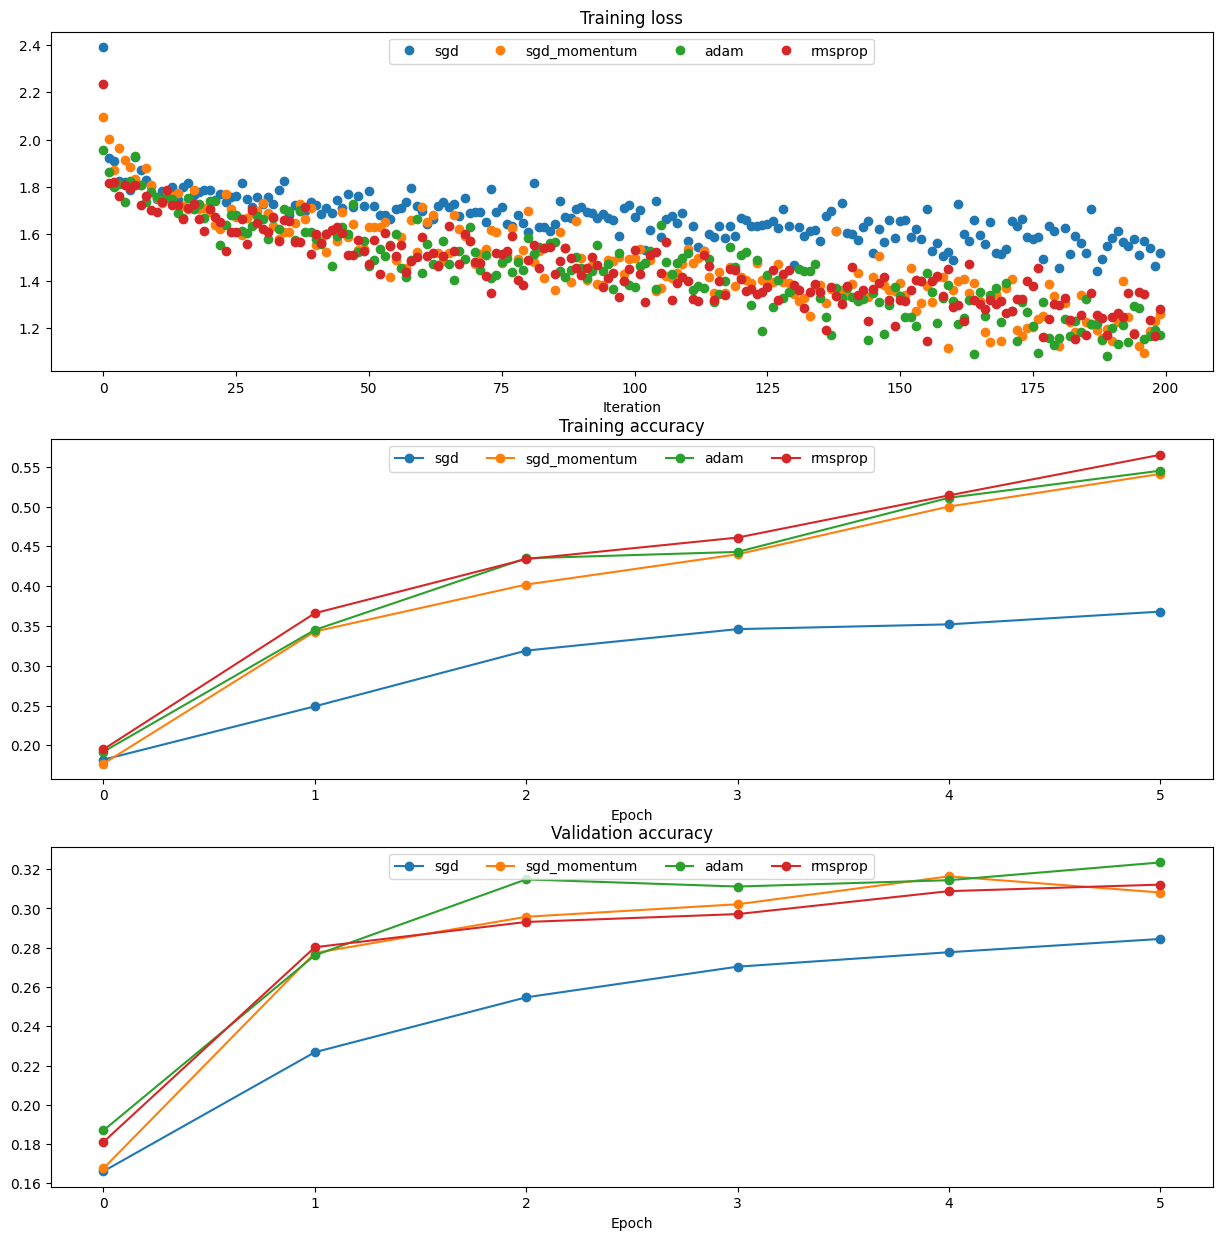

In [35]:
learning_rates = {'rmsprop': 1e-4, 'adam': 1e-3}
for update_rule in ['adam', 'rmsprop']:
  print('running with ', update_rule)
  model = FullyConnectedNet([100, 100, 100, 100, 100], weight_scale=5e-2, num_classes=6)

  solver = Solver(model, small_data,
                  num_epochs=5, batch_size=100,
                  update_rule=update_rule,
                  optim_config={
                    'learning_rate': learning_rates[update_rule]
                  },
                  verbose=True)
  solvers[update_rule] = solver
  solver.train()
  print()

plt.subplot(3, 1, 1)
plt.title('Training loss')
plt.xlabel('Iteration')

plt.subplot(3, 1, 2)
plt.title('Training accuracy')
plt.xlabel('Epoch')

plt.subplot(3, 1, 3)
plt.title('Validation accuracy')
plt.xlabel('Epoch')

for update_rule, solver in list(solvers.items()):
  plt.subplot(3, 1, 1)
  plt.plot(solver.loss_history, 'o', label=update_rule)

  plt.subplot(3, 1, 2)
  plt.plot(solver.train_acc_history, '-o', label=update_rule)

  plt.subplot(3, 1, 3)
  plt.plot(solver.val_acc_history, '-o', label=update_rule)

for i in [1, 2, 3]:
  plt.subplot(3, 1, i)
  plt.legend(loc='upper center', ncol=4)
plt.gcf().set_size_inches(15, 15)
plt.show()

## Inline Question 5:

AdaGrad, like Adam, is a per-parameter optimization method that uses the following update rule:

```
cache += dw**2
w += - learning_rate * dw / (np.sqrt(cache) + eps)
```

John notices that when he was training a network with AdaGrad that the updates became very small, and that his network was learning slowly. Using your knowledge of the AdaGrad update rule, why do you think the updates would become very small? Would Adam have the same issue?


## Answer:
In AdaGrad, the cache accumulates the squared gradients over time (cache += dw**2). Because squared numbers are strictly positive, the cache grows larger with every update.
As the denominator gets larger, the effective learning step shrinks toward zero, which causes the network to prematurely stop learning. Adam doesn't suffer from this issue because it uses a moving and decaying average for its second moment. The decay rate parameter (beta2) prevents the cache from growing infinitely, allowing Adam to maintain a steady and effective learning rate.


# Train a good model!
Train the best fully-connected model that you can on CINIC-10, storing your best model in the `best_model` variable. We require you to get at least 40% accuracy on the validation set using a fully-connected net.

Later in the assignment we will ask you to train the best convolutional network that you can on CINIC-10, and we would prefer that you spend your effort working on convolutional nets rather than fully-connected nets.

You might find it useful to complete the `BatchNormalization.ipynb` and `Dropout.ipynb` notebooks before completing this part, since those techniques can help you train powerful models.

In [36]:
best_model = None
################################################################################
# TODO: Train the best FullyConnectedNet that you can on CINIC-10. You might   #
# find batch/layer normalization and dropout useful. Store your best model in  #
# the best_model variable.                                                     #
################################################################################
# *****START OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****

hidden_dims = [100, 100, 100]
weight_scale = 5e-2
learning_rate = 1e-3

model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale, reg=1e-3)

solver = Solver(model, data,
                update_rule='adam',
                optim_config={
                  'learning_rate': learning_rate,
                },
                lr_decay=0.95,
                num_epochs=10,
                batch_size=100,
                print_every=100)

solver.train()
best_model = model

# *****END OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
################################################################################
#                              END OF YOUR CODE                                #
################################################################################

(Iteration 1 / 5390) loss: 15.590578
(Epoch 0 / 10) train acc: 0.174000; val_acc: 0.165179
(Iteration 101 / 5390) loss: 2.206995
(Iteration 201 / 5390) loss: 2.239984
(Iteration 301 / 5390) loss: 1.966574
(Iteration 401 / 5390) loss: 1.941095
(Iteration 501 / 5390) loss: 2.027268
(Epoch 1 / 10) train acc: 0.379000; val_acc: 0.344875
(Iteration 601 / 5390) loss: 2.076059
(Iteration 701 / 5390) loss: 1.951186
(Iteration 801 / 5390) loss: 1.899529
(Iteration 901 / 5390) loss: 1.913431
(Iteration 1001 / 5390) loss: 1.859901
(Epoch 2 / 10) train acc: 0.406000; val_acc: 0.374595
(Iteration 1101 / 5390) loss: 1.735783
(Iteration 1201 / 5390) loss: 1.793626
(Iteration 1301 / 5390) loss: 1.762204
(Iteration 1401 / 5390) loss: 1.749936
(Iteration 1501 / 5390) loss: 1.619113
(Iteration 1601 / 5390) loss: 1.644561
(Epoch 3 / 10) train acc: 0.434000; val_acc: 0.384306
(Iteration 1701 / 5390) loss: 1.626536
(Iteration 1801 / 5390) loss: 1.641724
(Iteration 1901 / 5390) loss: 1.895415
(Iteration 2001

# Test your model!
Run your best model on the validation and test sets. You should achieve above 40% accuracy on the validation set.

In [37]:
y_test_pred = np.argmax(best_model.loss(data['X_test']), axis=1)
y_val_pred = np.argmax(best_model.loss(data['X_val']), axis=1)
print('Validation set accuracy: ', (y_val_pred == data['y_val']).mean())
print('Test set accuracy: ', (y_test_pred == data['y_test']).mean())

Validation set accuracy:  0.41039725355566453
Test set accuracy:  0.4066300510003923
